## Imports

In [1]:
import importlib
import Diffusion
import LossFunctions
import ConsistencyModels
import  FlowMatching
from ConsistencyModels import ConsistencyModel
import dist_utils


importlib.reload(Diffusion)
importlib.reload(LossFunctions)
importlib.reload(ConsistencyModels)
importlib.reload(FlowMatching)
importlib.reload(dist_utils)


<module 'dist_utils' from 'C:\\Users\\orine\\PycharmProjects\\finalThesis\\dist_utils.py'>

In [2]:
import matplotlib.pyplot as plt
import torch
import numpy as np

## Sample Data

In [3]:
mu_list = [np.array([-5, 4]),
           np.array([5, -4]),
           # np.array([3, 5]),np.array([-1, 5]), np.array([0, 0]), np.array([5, -1]),np.array([-5, -1]), np.array([2, 1]),np.array([1, -7])
           ]

point_l = [[int(p[1]), int(p[0])] for p in mu_list]

mu_list = [torch.tensor(p, dtype=torch.float64) for p in point_l]

# Convert Sigma_list to 3D covariance matrices
Sigma_list = [
    torch.tensor([[2,0.12],[0.12,0.5]], dtype=torch.float64)
] * len(mu_list)

# Mixture weights
alpha =torch.tensor( [1 / len(mu_list)] * len(mu_list),dtype=torch.float64)
# Generate samples
device = 'cpu'  # Change to 'cuda' if using a GPU
# X = dist_utils.generate_mog_samples(n_samples, mu_list, Sigma_list, alpha )


mog_means = [
    torch.tensor([5.0], dtype=torch.float64),
    # torch.tensor([-5.0], dtype=torch.float64),

]
mog_variances = [torch.tensor([.25], dtype=torch.float64),
     # torch.tensor([.25], dtype=torch.float64),
     ]
weights = torch.tensor([1.,
                        # .5
                        ], dtype=torch.float64)


In [4]:
X = dist_utils.generate_mog_samples(50_000, mu_list, Sigma_list, alpha).float().to(device)

## Diffusion Model

### Regular

In [ ]:
nfeatures= X.shape[1]
model_diff = Diffusion.DiffusionModel(nfeatures=nfeatures, nunits=128*2, condition=False,condition_on=1,nblocks=3)
losses = model_diff.train_model(X, nepochs=100, batch_size=2048,condition_on=1)

In [ ]:
model_diff.eval()

gen_samples,_=model_diff.sample_ddim( 1_000, condition_x=None, device="cpu", eta=0.0, t_start=None, t_end=None)
gen_samples=gen_samples.detach().numpy()

In [ ]:
X_cpu = X.cpu()
plt.figure(figsize=(8, 8))
plt.scatter(X_cpu[:, 0], X_cpu[:, 1], color="blue", alpha=0.5, label="Real", s=10)
plt.scatter(gen_samples[:, 0], gen_samples[:, 1], color="red", alpha=0.5, label="Generated", s=10)
plt.title(f"Real vs Generated Samples ")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Conditional

In [ ]:
nfeatures= X.shape[1]
model_cond_diff =Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=4, nunits=128, condition=True,condition_on=1)
losses = model_cond_diff.train_model(X, nepochs=100, batch_size=3*2048,condition_on=1)

In [ ]:
model_cond_diff.eval()
condition= torch.tensor([5.]).view(1, -1).repeat(1_000, 1)
gen_samples,_=model_cond_diff.sample_ddim( 1_000, condition_x=condition, device="cpu", eta=0.0, t_start=None, t_end=None)
gen_samples=gen_samples.detach().numpy()

In [ ]:
import matplotlib.pyplot as plt
import torch
X_cpu = X.cpu()
plt.figure(figsize=(8, 8))
plt.scatter(X_cpu[:, 0], X_cpu[:, 1], color="blue", alpha=0.5, label="Real", s=10)
plt.scatter(gen_samples[:, 0], gen_samples[:, 1], color="red", alpha=0.5, label="Generated", s=10)
plt.title(f"Real vs Generated Samples ")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## MMD

In [ ]:
import torch

# Create two vectors: one from N(0, 1), another from N(10, 1)
a = torch.randn(100, 1)              # Mean 0, Std 1
b = torch.randn(100, 1) + 10         # Mean 10, Std 1

# Initialize MMD loss with default RBF kernel
mmd_loss = LossFunctions.MMDLoss(kernel=LossFunctions.RBF())

# Compute the MMD loss
loss = mmd_loss(a, b)

print("MMD Loss between N(0,1) and N(10,1):", loss.item())


## Consistency Models

### Regular

In [6]:
import matplotlib.pyplot as plt
import torch

def sample_and_plot(model, X, name="mog", device="cpu", steps=[80.0, 40.0, 20.0, 10.0, 5.0],n_samples=5_000):
    """
    Sample from the model and plot both the real (X) and generated samples in 2D.
    Assumes X.shape[1] == 2.
    """
    assert X.shape[1] == 2, "This function only supports 2D data for plotting."

    # model.eval()
    with torch.no_grad():
        z = torch.randn(n_samples,X.shape[1])*steps[0]
        xh = model.sample(z, steps).cpu()

    X_cpu = X.cpu()

    plt.figure(figsize=(8, 8))
    plt.scatter(X_cpu[:, 0], X_cpu[:, 1], color="blue", alpha=0.5, label="Real", s=10)
    plt.scatter(xh[:, 0], xh[:, 1], color="red", alpha=0.5, label="Generated", s=10)
    plt.title(f"Real vs Generated Samples ({name})")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    # plt.savefig(f"./contents/ct_{name}_scatter.png")
    plt.show()


In [7]:
condition=0
B, C = X.shape
D = 128
input_dim = C - condition
cond_dim = condition
Cos_model = ConsistencyModel(nfeatures=input_dim, condition_on=cond_dim, nunits=D)
# model=train_consistency(Cos_model,X, n_epoch=100, device=device, name="mog",condition=0)

In [13]:
Cos_model.train_model(X=X, nepochs= 100, batch_size=256,device= "cpu", condition=0)

loss: 0.008026, mu: 0.9993: 100%|██████████| 100/100 [14:42<00:00,  8.82s/it]


ConsistencyModel(
  (input_layer): Linear(in_features=2, out_features=128, bias=True)
  (time_embed): TimeEmbedding(
    (proj1): Linear(in_features=32, out_features=512, bias=True)
    (proj2): Linear(in_features=512, out_features=128, bias=True)
  )
  (net): GenericNN(
    (norm_input): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    (input_layer): Linear(in_features=128, out_features=128, bias=True)
    (res_blocks): Sequential(
      (0): MLPBlock(
        (block): Sequential(
          (0): Linear(in_features=128, out_features=128, bias=True)
          (1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (2): Swish()
          (3): Linear(in_features=128, out_features=128, bias=True)
          (4): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (5): Swish()
        )
      )
      (1): MLPBlock(
        (block): Sequential(
          (0): Linear(in_features=128, out_features=128, bias=True)
          (1): LayerNorm((128,), eps=1e-05, elem

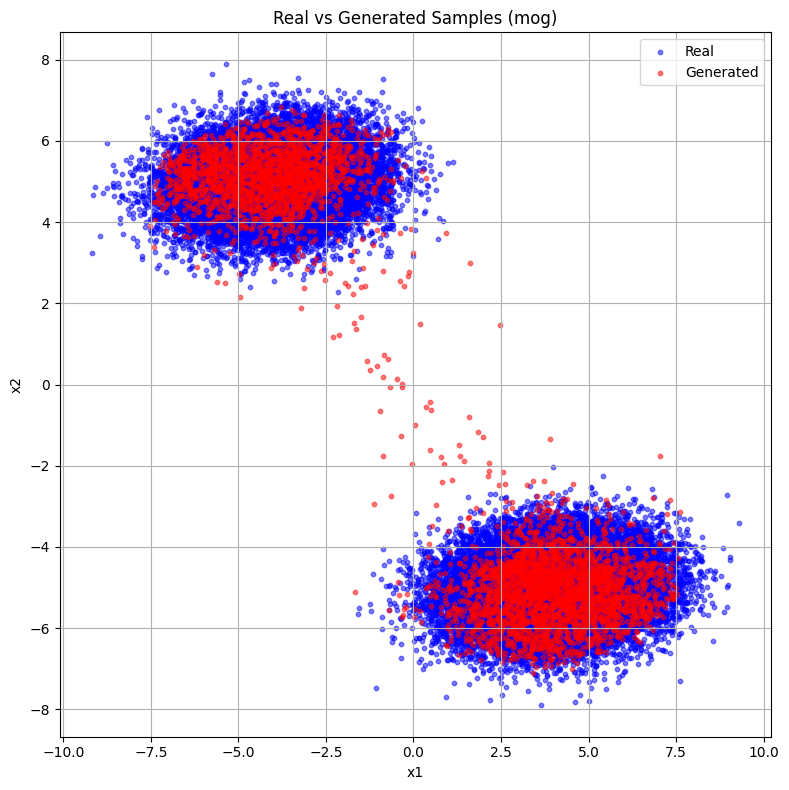

In [14]:
sample_and_plot(Cos_model, X, name="mog", device="cpu", steps=[50.,10.,5.,2.])

### Conditional

In [11]:
condition=1
B, C = X.shape
D = 128
input_dim = C - condition
cond_dim = condition
Cos_model = ConsistencyModel(input_dim= input_dim, cond_dim=cond_dim, D=D)

TypeError: __init__() got an unexpected keyword argument 'input_dim'

In [ ]:
Cos_model.train_model(X=X, n_epoch= 100, device= "cpu", condition=1)

In [ ]:
steps=[80.0, 40.0, 20.0, 10.0, 5.0,1.]
Cos_model.eval()
with torch.no_grad():
    z = torch.randn(1000,1)*steps[0]
    xh = Cos_model.sample(z, steps,cond=torch.tensor([5.]).repeat(1000,1)).cpu()

In [ ]:
import matplotlib.pyplot as plt

# Assuming xh is a torch tensor
xh_cpu = xh.detach().cpu().numpy()

plt.hist(xh_cpu, bins=50)  # You can adjust number of bins
plt.title("Histogram of xh")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()


## FM

### Regular

In [6]:
### Regular
input_dim = 2  #4mog_means[0].shape[0]
y_dim = 0  #mu_list[0].shape[0] - input_dim
hidden_dim = 256
depth = 4


In [7]:

# init flow
vf_x_y = FlowMatching.FMModel(nfeatures=input_dim,
                                   condition_on=y_dim,
                                   nunits=hidden_dim,
                                   nblocks=depth,
                                   device=device)  # train




In [8]:
vf_x_y.train_FM(lr=0.001, batch_size=1024, X=X, nepochs=1)

loss: 6.578055: 100%|██████████| 1/1 [00:06<00:00,  6.87s/it]


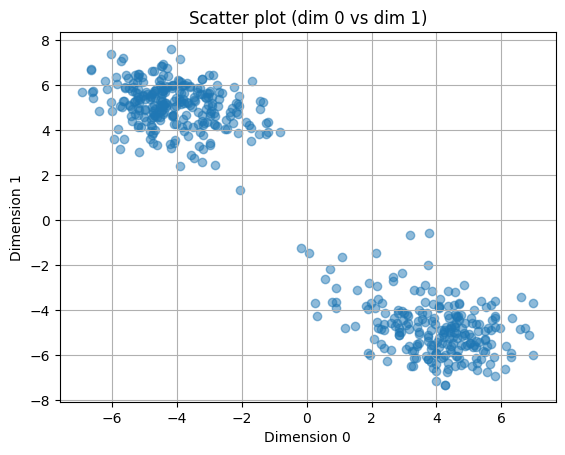

In [9]:
import matplotlib.pyplot as plt

xh_cpu = vf_x_y.sample(500).detach().cpu().numpy()
plt.scatter(xh_cpu[:, 0], xh_cpu[:, 1], alpha=0.5)  # or [:, 0] vs [:, 2], etc.
plt.title("Scatter plot (dim 0 vs dim 1)")
plt.xlabel("Dimension 0")
plt.ylabel("Dimension 1")
plt.grid(True)
plt.show()

### Conditional

In [11]:
input_dim = mog_means[0].shape[0]
y_dim = mu_list[0].shape[0] - input_dim
hidden_dim=256
depth=4
print(y_dim)

1


In [12]:
vf_y_cond_x = FlowMatching.FMModel(nfeatures=input_dim,
                                   condition_on=y_dim,
                                   nunits=hidden_dim,
                                   nblocks=depth,
                                   device=device)
vf_y_cond_x.train_FM(lr=0.001, batch_size=1024, X=X, nepochs=2)
# train

loss: 2.115551: 100%|██████████| 2/2 [00:10<00:00,  5.25s/it]


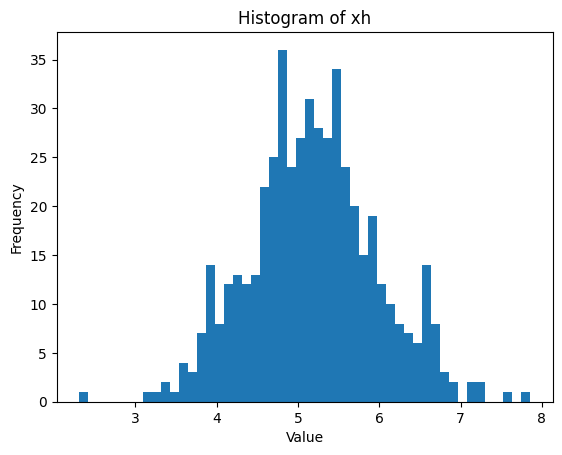

In [14]:
import matplotlib.pyplot as plt

xh_cpu=vf_y_cond_x.sample(500,torch.tensor([-5.])).detach().cpu().numpy()

plt.hist(xh_cpu, bins=50)  # You can adjust number of bins
plt.title("Histogram of xh")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()